METRICMIND — DATASET


,order_id,region,quarter,revenue,cost,profit,margin_pct
0,1001,Europe,Q1,12000,8000,4000,33.33
1,1002,Europe,Q1,15000,9000,6000,40.00
2,1003,Asia,Q1,10000,6500,3500,35.00
3,1004,North America,Q1,18000,12000,6000,33.33
4,1005,Europe,Q2,14000,10000,4000,28.57
5,1006,Asia,Q2,11000,7000,4000,36.36
6,1007,Europe,Q2,9000,7500,1500,16.67
7,1008,North America,Q2,20000,13000,7000,35.00
8,1009,Asia,Q3,13000,8000,5000,38.46
9,1010,Europe,Q3,10000,7500,2500,25.00



METRIC DEFINITIONS


,Metric,Definition
0,revenue,Sum of order revenue
1,cost,Sum of order cost
2,profit,Revenue minus cost
3,margin,Total profit / total revenue * 100



TEST QUESTION
MetricMind business analysis
Region: Europe
Quarter: Q2
Orders: 2
Revenue: 23,000.00
Cost: 17,500.00
Profit: 5,500.00
Profit margin: 23.91%
Metrics calculated using the approved definitions.


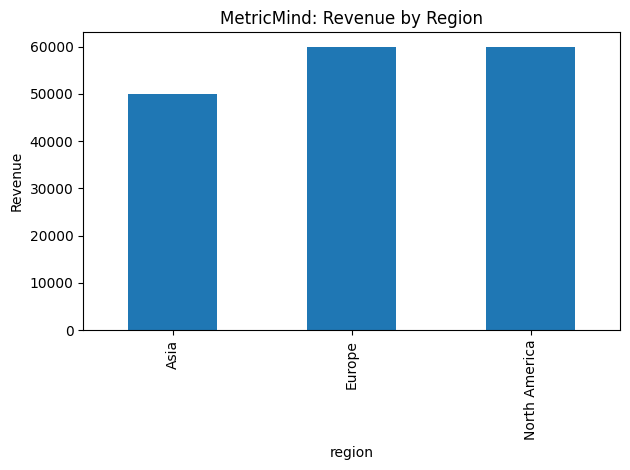


SUCCESS: Dataset, metric definitions, and chart created.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Sample business data
data = {
    "order_id": range(1001, 1013),
    "region": [
        "Europe", "Europe", "Asia", "North America",
        "Europe", "Asia", "Europe", "North America",
        "Asia", "Europe", "Asia", "North America"
    ],
    "quarter": ["Q1", "Q1", "Q1", "Q1", "Q2", "Q2",
                "Q2", "Q2", "Q3", "Q3", "Q3", "Q3"],
    "revenue": [12000,15000,10000,18000,14000,11000,
                9000,20000,13000,10000,16000,22000],
    "cost": [8000,9000,6500,12000,10000,7000,
             7500,13000,8000,7500,9500,14000]
}

df = pd.DataFrame(data)
df["profit"] = df["revenue"] - df["cost"]
df["margin_pct"] = (df["profit"] / df["revenue"] * 100).round(2)

# 2. Approved metric definitions
METRICS = {
    "revenue": "Sum of order revenue",
    "cost": "Sum of order cost",
    "profit": "Revenue minus cost",
    "margin": "Total profit / total revenue * 100"
}

def analyze(region=None, quarter=None):
    result = df.copy()

    if region:
        result = result[result["region"].str.lower() == region.lower()]

    if quarter:
        result = result[result["quarter"].str.upper() == quarter.upper()]

    if result.empty:
        return None

    revenue = result["revenue"].sum()
    cost = result["cost"].sum()
    profit = revenue - cost
    margin = profit / revenue * 100 if revenue else 0

    return {
        "Orders": len(result),
        "Revenue": revenue,
        "Cost": cost,
        "Profit": profit,
        "Profit margin (%)": round(margin, 2)
    }

# 3. Simple question interface
def metricmind(question):
    q = question.lower()
    region = next(
        (r for r in df["region"].unique() if r.lower() in q), None
    )
    quarter = next(
        (x for x in df["quarter"].unique() if x.lower() in q), None
    )

    if not any(word in q for word in
               ["revenue", "sales", "cost", "profit", "margin", "performance"]):
        return "Try asking about revenue, sales, cost, profit, or margin."

    result = analyze(region, quarter)

    if result is None:
        return "No matching records found."

    lines = [
        f"MetricMind business analysis",
        f"Region: {region or 'All regions'}",
        f"Quarter: {quarter or 'All quarters'}",
        f"Orders: {result['Orders']}",
        f"Revenue: {result['Revenue']:,.2f}",
        f"Cost: {result['Cost']:,.2f}",
        f"Profit: {result['Profit']:,.2f}",
        f"Profit margin: {result['Profit margin (%)']}%"
    ]

    if "margin" in q:
        lines.append("Definition: Total profit / total revenue × 100.")
    elif "profit" in q:
        lines.append("Definition: Total revenue minus total cost.")
    else:
        lines.append("Metrics calculated using the approved definitions.")

    return "\n".join(lines)

# 4. Verify results and show the dataset
print("METRICMIND — DATASET")
display(df)

print("\nMETRIC DEFINITIONS")
display(pd.DataFrame(
    list(METRICS.items()), columns=["Metric", "Definition"]
))

print("\nTEST QUESTION")
print(metricmind("Show European revenue in Q2"))

# 5. Create a regional revenue chart
regional = df.groupby("region")["revenue"].sum().sort_values()

regional.plot(kind="bar", title="MetricMind: Revenue by Region")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

# 6. Save deliverables
df.to_csv("metricmind_sales.csv", index=False)

with open("metricmind_metrics.md", "w") as f:
    f.write("# MetricMind — Metric Definitions\n\n")
    for name, definition in METRICS.items():
        f.write(f"- **{name.title()}:** {definition}\n")

print("\nSUCCESS: Dataset, metric definitions, and chart created.")

In [2]:
metricmind("Show European revenue in Q2")

'MetricMind business analysis\nRegion: Europe\nQuarter: Q2\nOrders: 2\nRevenue: 23,000.00\nCost: 17,500.00\nProfit: 5,500.00\nProfit margin: 23.91%\nMetrics calculated using the approved definitions.'

METRICMIND: REGIONAL BUSINESS ANALYSIS


,Region,Orders,Revenue,Cost,Profit,Margin_Pct
0,Asia,4,50000,31000,19000,38.0
1,Europe,5,60000,42000,18000,30.0
2,North America,3,60000,39000,21000,35.0


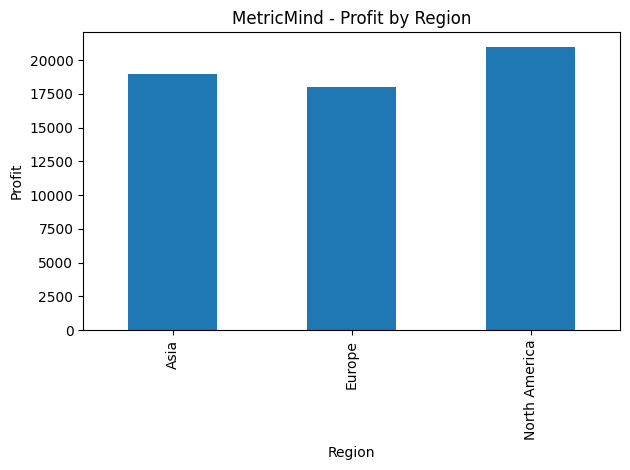

Regional analysis completed successfully!


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Use the existing dataset, or load the saved CSV
if "df" in globals():
    sales = df.copy()
else:
    sales = pd.read_csv("metricmind_sales.csv")

# Standardize column names
sales.columns = [str(c).strip().title() for c in sales.columns]

# Calculate business metrics
sales["Profit"] = sales["Revenue"] - sales["Cost"]
sales["Margin_Pct"] = (
    sales["Profit"] / sales["Revenue"].replace(0, float("nan"))
) * 100

# Compare performance by region
summary = sales.groupby("Region").agg(
    Orders=("Revenue", "count"),
    Revenue=("Revenue", "sum"),
    Cost=("Cost", "sum"),
    Profit=("Profit", "sum")
).reset_index()

summary["Margin_Pct"] = (
    summary["Profit"] / summary["Revenue"].replace(0, float("nan"))
) * 100

print("METRICMIND: REGIONAL BUSINESS ANALYSIS")
display(summary.round(2))

# Visualize regional profit
summary.plot(
    x="Region",
    y="Profit",
    kind="bar",
    legend=False,
    title="MetricMind - Profit by Region",
    ylabel="Profit"
)
plt.tight_layout()
plt.show()

# Save the analysis output
summary.to_csv("metricmind_regional_analysis.csv", index=False)
print("Regional analysis completed successfully!")

In [4]:
import pandas as pd
import re

# Reuse the existing dataset
data = sales.copy() if "sales" in globals() else (
    df.copy() if "df" in globals() else pd.read_csv("metricmind_sales.csv")
)

data.columns = [str(c).strip().lower().replace(" ", "_") for c in data.columns]

required = {"region", "revenue", "cost"}
missing = required - set(data.columns)

if missing:
    raise ValueError(f"Dataset is missing required columns: {missing}")

data["revenue"] = pd.to_numeric(data["revenue"], errors="coerce")
data["cost"] = pd.to_numeric(data["cost"], errors="coerce")
data["profit"] = data["revenue"] - data["cost"]
data["margin_pct"] = (
    data["profit"] / data["revenue"].replace(0, float("nan")) * 100
)

# Add quarter information if a date column exists
date_col = next(
    (c for c in ["order_date", "date", "orderdate"] if c in data.columns),
    None
)

if date_col:
    dates = pd.to_datetime(data[date_col], errors="coerce")
    data["quarter"] = "Q" + dates.dt.quarter.astype("Int64").astype(str)
elif "quarter" in data.columns:
    data["quarter"] = data["quarter"].astype(str).str.upper()

def metricmind_analyze(question):
    q = question.lower()

    # Identify the requested region
    regions = data["region"].dropna().astype(str).unique()
    region = next(
        (r for r in regions if r.lower() in q),
        None
    )

    # Identify requested quarter if available
    quarter = next(
        (f"Q{i}" for i in range(1, 5) if f"q{i}" in q),
        None
    )

    result = data.copy()

    if region:
        result = result[result["region"].astype(str).str.lower() == region.lower()]

    if quarter and "quarter" in result.columns:
        result = result[result["quarter"].astype(str).str.upper() == quarter]

    if result.empty:
        return "No matching data found. Check the region or quarter."

    revenue = result["revenue"].sum()
    cost = result["cost"].sum()
    profit = revenue - cost
    margin = (profit / revenue * 100) if revenue else 0

    if "margin" in q:
        answer = f"Profit margin: {margin:.2f}%"
    elif "profit" in q:
        answer = f"Profit: {profit:,.2f}"
    elif "cost" in q:
        answer = f"Cost: {cost:,.2f}"
    else:
        answer = f"Revenue: {revenue:,.2f}"

    print("METRICMIND BUSINESS ANALYSIS")
    print("Question:", question)
    print("Region:", region or "All regions")
    print("Quarter:", quarter or "All available periods")
    print(answer)
    print(f"Orders/records: {len(result)}")
    print(f"Revenue: {revenue:,.2f}")
    print(f"Cost: {cost:,.2f}")
    print(f"Profit: {profit:,.2f}")
    print(f"Profit margin: {margin:.2f}%")

    return result

# Test the analyzer
metricmind_analyze("Show European revenue in Q2")

METRICMIND BUSINESS ANALYSIS
Question: Show European revenue in Q2
Region: Europe
Quarter: Q2
Revenue: 23,000.00
Orders/records: 2
Revenue: 23,000.00
Cost: 17,500.00
Profit: 5,500.00
Profit margin: 23.91%


,order_id,region,quarter,revenue,cost,profit,margin_pct
4,1005,Europe,Q2,14000,10000,4000,28.571429
6,1007,Europe,Q2,9000,7500,1500,16.666667


In [5]:
metricmind_analyze("Show profit in Europe")
metricmind_analyze("Show cost in Asia")
metricmind_analyze("Show profit margin in Europe")

METRICMIND BUSINESS ANALYSIS
Question: Show profit in Europe
Region: Europe
Quarter: All available periods
Profit: 18,000.00
Orders/records: 5
Revenue: 60,000.00
Cost: 42,000.00
Profit: 18,000.00
Profit margin: 30.00%
METRICMIND BUSINESS ANALYSIS
Question: Show cost in Asia
Region: Asia
Quarter: All available periods
Cost: 31,000.00
Orders/records: 4
Revenue: 50,000.00
Cost: 31,000.00
Profit: 19,000.00
Profit margin: 38.00%
METRICMIND BUSINESS ANALYSIS
Question: Show profit margin in Europe
Region: Europe
Quarter: All available periods
Profit margin: 30.00%
Orders/records: 5
Revenue: 60,000.00
Cost: 42,000.00
Profit: 18,000.00
Profit margin: 30.00%


,order_id,region,quarter,revenue,cost,profit,margin_pct
0,1001,Europe,Q1,12000,8000,4000,33.333333
1,1002,Europe,Q1,15000,9000,6000,40.000000
4,1005,Europe,Q2,14000,10000,4000,28.571429
6,1007,Europe,Q2,9000,7500,1500,16.666667
9,1010,Europe,Q3,10000,7500,2500,25.000000


In [7]:
# MetricMind: Central Metric Governance Layer

METRIC_DEFINITIONS = {
    "revenue": {
        "formula": "Sum of revenue",
        "description": "Total sales revenue"
    },
    "cost": {
        "formula": "Sum of cost",
        "description": "Total business cost"
    },
    "profit": {
        "formula": "Revenue - Cost",
        "description": "Revenue remaining after costs"
    },
    "profit_margin": {
        "formula": "(Profit / Revenue) * 100",
        "description": "Profit as a percentage of revenue"
    }
}

def calculate_governed_metrics(data):
    required = {"revenue", "cost"}
    missing = required - set(data.columns)

    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    revenue = pd.to_numeric(data["revenue"], errors="coerce").sum()
    cost = pd.to_numeric(data["cost"], errors="coerce").sum()
    profit = revenue - cost
    margin = (profit / revenue * 100) if revenue != 0 else 0

    return {
        "revenue": round(float(revenue), 2),
        "cost": round(float(cost), 2),
        "profit": round(float(profit), 2),
        "profit_margin": round(float(margin), 2)
    }

print("METRICMIND GOVERNED METRIC DEFINITIONS")
for name, definition in METRIC_DEFINITIONS.items():
    print(f"\n{name.upper()}")
    print("Formula:", definition["formula"])
    print("Meaning:", definition["description"])

print("\nGOVERNED METRIC RESULTS")
governed_results = calculate_governed_metrics(data)
display(pd.DataFrame(
    list(governed_results.items()),
    columns=["Metric", "Value"]
))

METRICMIND GOVERNED METRIC DEFINITIONS

REVENUE
Formula: Sum of revenue
Meaning: Total sales revenue

COST
Formula: Sum of cost
Meaning: Total business cost

PROFIT
Formula: Revenue - Cost
Meaning: Revenue remaining after costs

PROFIT_MARGIN
Formula: (Profit / Revenue) * 100
Meaning: Profit as a percentage of revenue

GOVERNED METRIC RESULTS


,Metric,Value
0,revenue,170000.00
1,cost,112000.00
2,profit,58000.00
3,profit_margin,34.12


In [10]:
# MetricMind: Data Quality Validation

def validate_sales_data(data):
    required_columns = ["region", "revenue", "cost"]
    missing_columns = [
        col for col in required_columns if col not in data.columns
    ]

    if missing_columns:
        print("FAILED: Missing columns:", missing_columns)
        return

    checks = []

    checks.append({
        "Check": "Missing values",
        "Issues": int(data[required_columns].isnull().sum().sum())
    })

    checks.append({
        "Check": "Duplicate rows",
        "Issues": int(data.duplicated().sum())
    })

    checks.append({
        "Check": "Negative revenue",
        "Issues": int((data["revenue"] < 0).sum())
    })

    checks.append({
        "Check": "Negative cost",
        "Issues": int((data["cost"] < 0).sum())
    })

    report = pd.DataFrame(checks)
    report["Status"] = report["Issues"].apply(
        lambda n: "PASS" if n == 0 else "REVIEW"
    )

    print("METRICMIND DATA QUALITY REPORT")
    display(report)

    if (report["Issues"] > 0).any():
        print("Some records need review before business analysis.")
    else:
        print("All configured data quality checks passed.")

# Run validation on the current dataset
validate_sales_data(data)

METRICMIND DATA QUALITY REPORT


,Check,Issues,Status
0,Missing values,0,PASS
1,Duplicate rows,0,PASS
2,Negative revenue,0,PASS
3,Negative cost,0,PASS


All configured data quality checks passed.


=== METRICMIND BUSINESS INSIGHTS REPORT ===


,region,Records,Revenue,Cost,Profit,Profit_Margin_Pct
2,North America,3,60000,39000,21000,35.0
0,Asia,4,50000,31000,19000,38.0
1,Europe,5,60000,42000,18000,30.0



METRICMIND - BUSINESS INSIGHTS REPORT

Total records analyzed: 12
Total revenue: 170,000.00
Total cost: 112,000.00
Total profit: 58,000.00
Overall profit margin: 34.12%

Highest-profit region: North America
Profit: 21,000.00

Lowest-profit region: Europe
Profit: 18,000.00

Note: Insights describe the supplied dataset and do not establish causes.


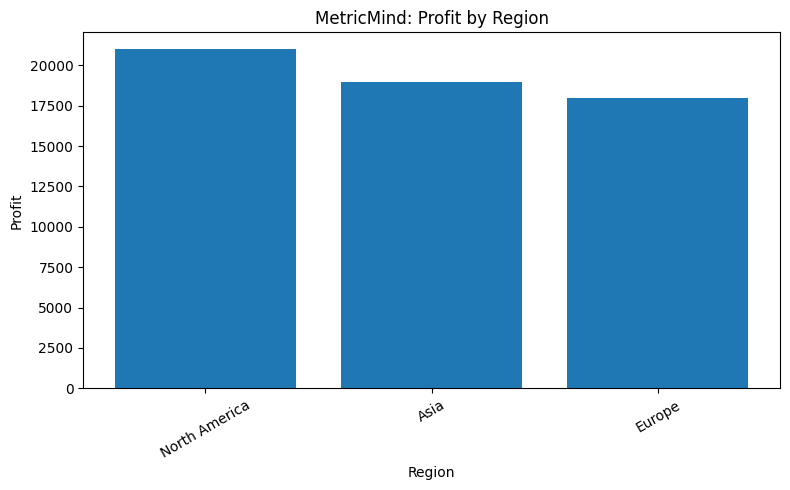


Business insights report and CSV created successfully.


In [11]:
# MetricMind: Regional Business Insights Report

import pandas as pd
import matplotlib.pyplot as plt

# Reuse the existing dataset
if "data" in globals() and isinstance(data, pd.DataFrame):
    insight_data = data.copy()
elif "sales" in globals() and isinstance(sales, pd.DataFrame):
    insight_data = sales.copy()
else:
    insight_data = pd.read_csv("metricmind_sales.csv")

# Standardize column names
insight_data.columns = [
    str(c).strip().lower().replace(" ", "_")
    for c in insight_data.columns
]

required = {"region", "revenue", "cost"}
missing = required - set(insight_data.columns)

if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Validate and prepare data
insight_data["revenue"] = pd.to_numeric(
    insight_data["revenue"], errors="coerce"
)
insight_data["cost"] = pd.to_numeric(
    insight_data["cost"], errors="coerce"
)

insight_data = insight_data.dropna(
    subset=["region", "revenue", "cost"]
).copy()

if insight_data.empty:
    raise ValueError("No valid sales records available.")

insight_data["profit"] = (
    insight_data["revenue"] - insight_data["cost"]
)

# Summarize each region
insights = insight_data.groupby("region").agg(
    Records=("revenue", "size"),
    Revenue=("revenue", "sum"),
    Cost=("cost", "sum"),
    Profit=("profit", "sum")
).reset_index()

insights["Profit_Margin_Pct"] = (
    insights["Profit"] /
    insights["Revenue"].replace(0, float("nan")) * 100
)

insights = insights.sort_values("Profit", ascending=False)

print("=== METRICMIND BUSINESS INSIGHTS REPORT ===")
display(insights.round(2))

# Identify strongest and weakest regions by total profit
best_region = insights.loc[insights["Profit"].idxmax()]
worst_region = insights.loc[insights["Profit"].idxmin()]

total_revenue = insight_data["revenue"].sum()
total_cost = insight_data["cost"].sum()
total_profit = total_revenue - total_cost
overall_margin = (
    total_profit / total_revenue * 100
    if total_revenue != 0 else 0
)

report_lines = [
    "METRICMIND - BUSINESS INSIGHTS REPORT",
    "",
    f"Total records analyzed: {len(insight_data)}",
    f"Total revenue: {total_revenue:,.2f}",
    f"Total cost: {total_cost:,.2f}",
    f"Total profit: {total_profit:,.2f}",
    f"Overall profit margin: {overall_margin:.2f}%",
    "",
    f"Highest-profit region: {best_region['region']}",
    f"Profit: {best_region['Profit']:,.2f}",
    "",
    f"Lowest-profit region: {worst_region['region']}",
    f"Profit: {worst_region['Profit']:,.2f}",
    "",
    "Note: Insights describe the supplied dataset and do not establish causes."
]

report_text = "\n".join(report_lines)
print("\n" + report_text)

# Plot regional profit
plt.figure(figsize=(8, 5))
plt.bar(insights["region"].astype(str), insights["Profit"])
plt.title("MetricMind: Profit by Region")
plt.xlabel("Region")
plt.ylabel("Profit")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Save outputs for the final project package
insights.to_csv("metricmind_regional_insights.csv", index=False)

with open("metricmind_business_insights.txt", "w", encoding="utf-8") as f:
    f.write(report_text)

print("\nBusiness insights report and CSV created successfully.")

In [13]:
# MetricMind: Interactive Business Query Dashboard

import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

# Load existing data
if "data" in globals() and isinstance(data, pd.DataFrame):
    dashboard_data = data.copy()
elif "insight_data" in globals() and isinstance(insight_data, pd.DataFrame):
    dashboard_data = insight_data.copy()
else:
    dashboard_data = pd.read_csv("metricmind_sales.csv")

dashboard_data.columns = [
    str(c).strip().lower().replace(" ", "_")
    for c in dashboard_data.columns
]

dashboard_data["revenue"] = pd.to_numeric(
    dashboard_data["revenue"], errors="coerce"
)
dashboard_data["cost"] = pd.to_numeric(
    dashboard_data["cost"], errors="coerce"
)
dashboard_data = dashboard_data.dropna(
    subset=["region", "revenue", "cost"]
).copy()

dashboard_data["profit"] = (
    dashboard_data["revenue"] - dashboard_data["cost"]
)

dashboard_data["margin_pct"] = (
    dashboard_data["profit"]
    / dashboard_data["revenue"].replace(0, float("nan"))
    * 100
)

regions = sorted(dashboard_data["region"].astype(str).unique())

region_selector = widgets.Dropdown(
    options=["All Regions"] + regions,
    value="All Regions",
    description="Region:"
)

metric_selector = widgets.Dropdown(
    options=[
        ("Revenue", "revenue"),
        ("Cost", "cost"),
        ("Profit", "profit"),
        ("Profit Margin (%)", "margin_pct")
    ],
    value="revenue",
    description="Metric:"
)

run_button = widgets.Button(
    description="Analyze",
    button_style="primary",
    icon="search"
)

output = widgets.Output()

def run_dashboard(_):
    with output:
        clear_output(wait=True)

        selected_region = region_selector.value
        selected_metric = metric_selector.value

        subset = dashboard_data.copy()

        if selected_region != "All Regions":
            subset = subset[
                subset["region"].astype(str) == selected_region
            ]

        if selected_metric == "margin_pct":
            revenue_total = subset["revenue"].sum()
            profit_total = subset["profit"].sum()
            value = (
                profit_total / revenue_total * 100
                if revenue_total else float("nan")
            )
            metric_label = "Profit Margin"
            suffix = "%"
        else:
            value = subset[selected_metric].sum()
            metric_label = selected_metric.replace("_", " ").title()
            suffix = ""

        print("METRICMIND DASHBOARD")
        print("Region:", selected_region)
        print("Metric:", metric_label)
        print("Records analyzed:", len(subset))
        print(f"Result: {value:,.2f}{suffix}")

        if selected_metric != "margin_pct":
            regional_values = subset.groupby("region")[selected_metric].sum()

            if not regional_values.empty:
                regional_values.plot(
                    kind="bar",
                    title=f"{metric_label} by Region",
                    ylabel=metric_label
                )
                plt.tight_layout()
                plt.show()

run_button.on_click(run_dashboard)

display(
    widgets.VBox([
        widgets.HTML("<h3>MetricMind Business Dashboard</h3>"),
        region_selector,
        metric_selector,
        run_button,
        output
    ])
)

In [14]:
# MetricMind: Business Query Audit Log

import pandas as pd
from datetime import datetime, timezone
import ipywidgets as widgets
from IPython.display import display, clear_output

# Store audit records during this notebook session
if "metricmind_audit_log" not in globals():
    metricmind_audit_log = []

audit_region = widgets.Dropdown(
    options=["All Regions"] + sorted(
        dashboard_data["region"].astype(str).unique().tolist()
    ),
    description="Region:"
)

audit_metric = widgets.Dropdown(
    options=[
        ("Revenue", "revenue"),
        ("Cost", "cost"),
        ("Profit", "profit"),
        ("Profit Margin (%)", "margin_pct")
    ],
    description="Metric:"
)

audit_button = widgets.Button(
    description="Run & Log Query",
    button_style="primary"
)

audit_output = widgets.Output()

def run_audited_query(_):
    with audit_output:
        clear_output(wait=True)

        region = audit_region.value
        metric = audit_metric.value

        subset = dashboard_data.copy()

        if region != "All Regions":
            subset = subset[
                subset["region"].astype(str) == region
            ]

        if metric == "margin_pct":
            revenue = subset["revenue"].sum()
            profit = subset["profit"].sum()
            value = profit / revenue * 100 if revenue else 0
        else:
            value = subset[metric].sum()

        record = {
            "timestamp_utc": datetime.now(timezone.utc).isoformat(),
            "region": region,
            "metric": metric,
            "records_analyzed": len(subset),
            "result": round(float(value), 2)
        }

        metricmind_audit_log.append(record)

        print("QUERY COMPLETED")
        print("Region:", region)
        print("Metric:", metric)
        print(f"Result: {value:,.2f}")
        print("Audit record saved for this session.")

        display(pd.DataFrame(metricmind_audit_log))

audit_button.on_click(run_audited_query)

display(widgets.VBox([
    widgets.HTML("<h3>MetricMind Query Audit Log</h3>"),
    audit_region,
    audit_metric,
    audit_button,
    audit_output
]))

In [15]:
audit_df = pd.DataFrame(metricmind_audit_log)
audit_df.to_csv("metricmind_query_audit_log.csv", index=False)
print("Audit log exported successfully.")
display(audit_df)

Audit log exported successfully.


,timestamp_utc,region,metric,records_analyzed,result
0,2026-10-15T17:25:36.467063+00:00,Asia,profit,4,19000.0
1,2026-10-15T17:25:43.182966+00:00,Asia,revenue,4,50000.0
2,2026-10-15T17:25:52.003352+00:00,North America,margin_pct,3,35.0
3,2026-10-15T17:25:58.548016+00:00,North America,profit,3,21000.0
4,2026-10-15T17:26:32.339975+00:00,Asia,profit,4,19000.0
5,2026-10-15T17:26:37.048419+00:00,Asia,cost,4,31000.0
